## 1. Wczytanie danych i funkcje pomocnicze

Osiem tabel jednego meczu z `output/` (do wizualizacji per-mecz w sekcjach 10–11) oraz **wspólne tabele wszystkich meczów**: `events_all`, `players_all`, `formations_all`, `player_stats_all` i `team_stats_all`, które łączymy międzytabelarycznie w sekcjach 2–9 i 12–14. Tu też funkcje pomocnicze (Wilson, tabela warunkowa, R² płaszczyzny).


In [154]:
# Wczytanie: tabele JEDNEGO meczu (formacje, statystyki) + wspolne tabele wszystkich meczow
from pathlib import Path

import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
DATA = ROOT / "output"
FIGURES = DATA / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# jeden mecz - do wizualizacji per-mecz (sekcje 10-11)
MATCH = "match_1821123_Southampton_vs_Aston_Villa"

# wszystkie tabele, jakie produkuje scraper, trzymamy w jednym slowniku
match_tables = {
    name: pd.read_csv(DATA / f"{MATCH}_{name}.csv")
    for name in [
        "players",
        "metadata",
        "formations",
        "lookups",
        "minute_mapping",
        "player_stats",
        "shot_zones",
        "team_stats",
    ]
}

# do wizualizacji jednego meczu w sekcjach 10-11
formations = match_tables["formations"]
team_stats = match_tables["team_stats"]

print("mecz do wizualizacji:", MATCH)
for name, table in match_tables.items():
    print(f"  {name:<16} {str(table.shape):>14}")


mecz do wizualizacji: match_1821123_Southampton_vs_Aston_Villa
  players                (40, 23)
  metadata                (1, 58)
  formations             (99, 21)
  lookups                (243, 3)
  minute_mapping         (100, 4)
  player_stats          (4785, 9)
  shot_zones              (27, 8)
  team_stats            (1462, 7)


In [155]:
# Wszystkie mecze we wspolnych tabelach - do analizy miedzytabelarycznej
def load_all(suffix):
    files = sorted(DATA.glob(f"*_{suffix}.csv"))
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True), len(files)


events_all, n_matches = load_all("events")
players_all, _ = load_all("players")
formations_all, _ = load_all("formations")
player_stats_all, _ = load_all("player_stats")
team_stats_all, _ = load_all("team_stats")

print("meczow           :", n_matches)
print("events_all       :", events_all.shape)
print("players_all      :", players_all.shape)
print("formations_all   :", formations_all.shape)
print("player_stats_all :", player_stats_all.shape)
print("team_stats_all   :", team_stats_all.shape)
print()
print("zduplikowane wiersze w events_all:", events_all.duplicated().sum())
print("kolizje id w events_all          :", events_all["id"].duplicated().sum())


meczow           : 10
events_all       : (16249, 95)
players_all      : (443, 23)
formations_all   : (1078, 21)
player_stats_all : (51764, 9)
team_stats_all   : (15980, 7)

zduplikowane wiersze w events_all: 0
kolizje id w events_all          : 4


In [156]:
# Funkcje pomocnicze uzywane w dalszych sekcjach (zdefiniowane raz, na gorze)
def wilson_ci(k, n):
    """95% przedzial ufnosci Wilsona dla proporcji, w procentach."""
    if n == 0:
        return 0.0, 0.0
    z = 1.96
    p = k / n
    denom = 1 + z ** 2 / n
    center = (p + z ** 2 / (2 * n)) / denom
    half_width = z * ((p * (1 - p) / n + z ** 2 / (4 * n ** 2)) ** 0.5) / denom
    return 100 * (center - half_width), 100 * (center + half_width)


def cond_table(df, col, target="has_shot"):
    """P(target | col) z 95% przedzialem ufnosci Wilsona."""
    summary = df.groupby(col, observed=False).agg(
        cases=(target, "size"),
        hits=(target, "sum"),
    )
    summary["P %"] = (100 * summary["hits"] / summary["cases"]).round(2)

    intervals = []
    for k, n in zip(summary["hits"], summary["cases"]):
        low, high = wilson_ci(k, n)
        intervals.append(f"{low:.1f}-{high:.1f}")

    summary["95% CI"] = intervals
    return summary


def plane_r2(df, x1, x2, y):
    """R2 dopasowania plaszczyzny najmniejszych kwadratow y ~ x1 + x2."""
    X = np.column_stack([np.ones(len(df)), df[x1], df[x2]])
    y_true = df[y].to_numpy()

    beta, *_ = np.linalg.lstsq(X, y_true, rcond=None)
    y_pred = X @ beta

    ss_res = ((y_true - y_pred) ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    if ss_tot == 0:
        return 0.0
    return 1 - ss_res / ss_tot


print("available helpers: wilson_ci(), cond_table(), plane_r2()")


available helpers: wilson_ci(), cond_table(), plane_r2()


## 2. Cechy przestrzenne, progresja i cechy z `players_all`

Wzbogacenie `events_all` o:
1. **Cechy geometryczne i strefowe**: `goal_distance`, `in_box`, `golden_zone`, `shot_on_target`.
2. **Cechy progresji ruchu piłki**: `dx = end_x - x`, `dy = end_y - y` oraz `goal_progression` (ile jednostek bliżej środka bramki znalazła się piłka po zagraniu — zastępuje surowe `end_x`, które trywialnie koreluje z `x`).
3. **Cechy międzytabelaryczne z `players_all`**: wiek, wzrost, waga i ocena wykonawcy (`player_*`) oraz adresata podania (`receiver_*`).


In [157]:
# 1. Cechy przestrzenne w skali 0-100; bramka przeciwnika to punkt (100, 50).
events_all["goal_distance"] = np.hypot(100 - events_all["x"], 50 - events_all["y"])
events_all["in_box"] = (events_all["x"] >= 83) & (events_all["y"].between(21, 79))
events_all["golden_zone"] = (events_all["x"] >= 88) & (events_all["y"].between(36, 64))
events_all["shot_on_target"] = events_all["event_type"].isin(["Goal", "SavedShot"])

# 2. Cechy progresji (dla zdarzen majacych wspolrzedne koncowe, np. podan)
events_all["dx"] = events_all["end_x"] - events_all["x"]
events_all["dy"] = events_all["end_y"] - events_all["y"]
end_goal_distance = np.hypot(100 - events_all["end_x"], 50 - events_all["end_y"])
events_all["goal_progression"] = events_all["goal_distance"] - end_goal_distance

# 3. Dolaczenie cech wykonawcy i odbiorcy z players_all (po match_id + player_id)
player_info = players_all[
    ["match_id", "player_id", "age", "height_cm", "weight_kg", "final_rating"]
].drop_duplicates(subset=["match_id", "player_id"])

actor_info = player_info.rename(columns={
    "age": "player_age",
    "height_cm": "player_height_cm",
    "weight_kg": "player_weight_kg",
    "final_rating": "player_rating",
})
receiver_info = player_info.rename(columns={
    "player_id": "receiver_id",
    "age": "receiver_age",
    "height_cm": "receiver_height_cm",
    "weight_kg": "receiver_weight_kg",
    "final_rating": "receiver_rating",
})

# Jesli komorka jest uruchamiana ponownie, usuwamy stare kolumny przed merge
new_cols = [
    "player_age", "player_height_cm", "player_weight_kg", "player_rating",
    "receiver_age", "receiver_height_cm", "receiver_weight_kg", "receiver_rating",
]
events_all = events_all.drop(columns=[c for c in new_cols if c in events_all.columns])
events_all = events_all.merge(actor_info, on=["match_id", "player_id"], how="left")
events_all = events_all.merge(receiver_info, on=["match_id", "receiver_id"], how="left")

print("goal_distance    : min %.1f  max %.1f" % (
    events_all["goal_distance"].min(),
    events_all["goal_distance"].max(),
))
print("goal_progression : min %.1f  max %.1f" % (
    events_all["goal_progression"].min(),
    events_all["goal_progression"].max(),
))
print("pokrycie cech gracza w events_all   : %.1f%%" % (100 * events_all["player_height_cm"].notna().mean()))
print("pokrycie cech odbiorcy w podaniach  : %.1f%%" % (
    100 * events_all.loc[events_all["event_type"] == "Pass", "receiver_height_cm"].notna().mean()
))


goal_distance    : min 0.9  max 111.8
goal_progression : min -38.1  max 72.1
pokrycie cech gracza w events_all   : 98.9%
pokrycie cech odbiorcy w podaniach  : 82.7%


## 3. Selekcja kolumn i tabela międzytabelaryczna `player_match_df`

1. **Oczyszczenie `events_all`**: usuwamy identyfikatory, kody słownikowe (`event_type_value`, `outcome_type_value`, `card_type_value`, `formation_slot`), licznik sekund (`second`) oraz surowe współrzędne końcowe (`end_x`, `end_y` — zastąpione przez `dx`, `dy` i `goal_progression`).
2. **Budowa tabeli międzytabelarycznej `player_match_df` (poziom: zawodnik w meczu)** z zachowaniem pełnej wymiarowości:
   - **Normalizacja czasowa (`minutes_played` i statystyki per 90 min)**: czas gry wyliczamy z okien `formations_all` (`end_minute_expanded - start_minute_expanded`), odfiltrowujemy epizody (`minutes_played >= 15` i `touches >= 5`) i przeliczamy cechy zliczeniowe na 90 minut (`*_per90`), eliminując pozorny wpływ długości występu.
   - **Poprawny mianownik odsetków podań**: `head_pass_pct` oraz `long_ball_pct` są liczone wyłącznie względem wszystkich podań gracza (`is_pass == True`), analogicznie do `pass_accuracy_pct`.
   - **Wymiar przestrzenny i zmienność wewnątrzmeczowa**: pozycję taktyczną (`tactical_vertical`, `tactical_horizontal`) liczymy jako średnią ważoną czasem trwania każdego ustawienia z `formations_all`, a z `events_all` dodajemy rzeczywiste położenie i mobilność na boisku (`mean_x`, `mean_y`, `std_x`, `std_y`, `std_pass_length`).
   - **Pełny zestaw statystyk defensywnych i deduplikacja cech fizycznych**: uwzględniamy `interceptions_per90`, a korelacje stałych cech fizycznych (`height_cm`, `weight_kg`, `age`) raportujemy również po deduplikacji do unikalnych zawodników (`player_career_df`).


In [158]:
# 3A. Selekcja kolumn na poziomie pojedynczego zdarzenia (events_all)
EXCLUDED_COLS = [
    # identyfikatory
    "match_id", "event_index", "id", "event_id",
    "team_id", "player_id", "related_event_id",
    "opposite_related_event_id", "next_team_id", "next_player_id",
    "receiver_id", "related_player_id", "shirt_no", "qualifier_jersey_number",
    # czas i liczniki porzadkowe
    "minute", "second", "period_value",
    "minute_info_minute", "minute_info_expanded_minute",
    "minute_info_period", "minute_info_extra_time",
    # kody slownikowe (zmienne nominalne zakodowane liczbami)
    "event_field", "event_type_value", "outcome_type_value",
    "card_type_value", "formation_slot", "score",
    # surowe wspolrzedne koncowe (zastapione przez dx, dy i goal_progression)
    "end_x", "end_y", "qualifier_pass_end_x", "qualifier_pass_end_y",
]

MIN_COVERAGE = 0.5

selected_event_cols = []
for col in events_all.select_dtypes("number").columns:
    if col in EXCLUDED_COLS:
        continue
    if events_all[col].notna().mean() < MIN_COVERAGE:
        continue
    if events_all[col].dropna().isin([0, 1]).all():
        continue
    selected_event_cols.append(col)

# usun kolumny niosace te sama informacje (|r| > 0.99)
unique_event_cols = []
for col in selected_event_cols:
    for kept in unique_event_cols:
        if abs(events_all[col].corr(events_all[kept])) > 0.99:
            print(f"  pomijam {col}: to samo co {kept}")
            break
    else:
        unique_event_cols.append(col)

selected_event_cols = unique_event_cols

print("kolumny events_all po oczyszczeniu:", len(selected_event_cols))
for col in selected_event_cols:
    coverage = 100 * events_all[col].notna().mean()
    print(f"  {col:<26} pokrycie {coverage:5.1f}%")


kolumny events_all po oczyszczeniu: 17
  expanded_minute            pokrycie 100.0%
  x                          pokrycie 100.0%
  y                          pokrycie 100.0%
  pass_length                pokrycie  68.2%
  pass_angle                 pokrycie  68.2%
  goal_distance              pokrycie 100.0%
  dx                         pokrycie  68.4%
  dy                         pokrycie  68.4%
  goal_progression           pokrycie  68.4%
  player_age                 pokrycie  98.9%
  player_height_cm           pokrycie  98.9%
  player_weight_kg           pokrycie  98.9%
  player_rating              pokrycie  98.9%
  receiver_age               pokrycie  54.0%
  receiver_height_cm         pokrycie  54.0%
  receiver_weight_kg         pokrycie  54.0%
  receiver_rating            pokrycie  54.0%


In [159]:
# 3B. Tabela miedzytabelaryczna: ZAWODNIK W MECZU (players + formations + events + player_stats)
# 1) Bazowe cechy fizyczne i ocena z players_all
players_base = players_all[
    ["match_id", "team_id", "player_id", "player_name", "position",
     "is_first_eleven", "age", "height_cm", "weight_kg", "final_rating"]
].drop_duplicates(subset=["match_id", "player_id"]).copy()

# 2) Czas gry (minutes_played) i srednia pozycja taktyczna wazona czasem okna z formations_all (Poprawki 1 i 3)
formations_weighted = formations_all.assign(
    window_minutes=lambda d: (d["end_minute_expanded"] - d["start_minute_expanded"]).clip(lower=1),
    weighted_vert=lambda d: d["vertical"] * 10 * d["window_minutes"],
    weighted_horiz=lambda d: d["horizontal"] * 10 * d["window_minutes"],
)
tactical_agg = (
    formations_weighted.groupby(["match_id", "player_id"])
    .agg(
        minutes_played=("window_minutes", "sum"),
        weighted_vert_sum=("weighted_vert", "sum"),
        weighted_horiz_sum=("weighted_horiz", "sum"),
    )
    .assign(
        tactical_vertical=lambda d: d["weighted_vert_sum"] / d["minutes_played"],
        tactical_horizontal=lambda d: d["weighted_horiz_sum"] / d["minutes_played"],
    )[["minutes_played", "tactical_vertical", "tactical_horizontal"]]
    .reset_index()
)

# 3) Agregacja zachowan boiskowych z events_all per (match_id, player_id)
# Poprawka 2: odsetki head_pass_pct i long_ball_pct liczone wzgledem liczby podan (is_pass)
# Poprawka 3: rzeczywiste wspolrzedne boiskowe i rozrzut (mean_x, mean_y, std_x, std_y, std_pass_length)
player_events = events_all[events_all["player_id"].notna()].copy()
player_events["is_pass"] = player_events["event_type"] == "Pass"
player_events["pass_accurate"] = np.where(
    player_events["is_pass"],
    (player_events["outcome_type"] == "Successful").astype(float),
    np.nan,
)
player_events["pass_head"] = np.where(
    player_events["is_pass"],
    player_events["is_head_pass"].astype(float),
    np.nan,
)
player_events["pass_long"] = np.where(
    player_events["is_pass"],
    player_events["is_long_ball"].astype(float),
    np.nan,
)

events_agg = player_events.groupby(["match_id", "player_id"]).agg(
    touches=("is_touch", "sum"),
    mean_x=("x", "mean"),
    mean_y=("y", "mean"),
    std_x=("x", "std"),
    std_y=("y", "std"),
    mean_pass_length=("pass_length", "mean"),
    std_pass_length=("pass_length", "std"),
    mean_progression=("goal_progression", "mean"),
    pass_accuracy_pct=("pass_accurate", lambda s: 100 * s.mean()),
    head_pass_pct=("pass_head", lambda s: 100 * s.mean()),
    long_ball_pct=("pass_long", lambda s: 100 * s.mean()),
    shots=("is_shot", "sum"),
    key_passes=("is_key_pass", "sum"),
).reset_index()

# 4) Wybrane statystyki z player_stats_all (suma w meczu, w tym interceptions - Poprawka 4)
stats_map = {
    "aerialsWon": "aerials_won",
    "tackleSuccessful": "tackles_won",
    "dribblesWon": "dribbles_won",
    "interceptions": "interceptions",
}
stats_pivot = (
    player_stats_all[player_stats_all["stat_name"].isin(stats_map.keys())]
    .groupby(["match_id", "player_id", "stat_name"])["value"]
    .sum()
    .unstack(fill_value=0.0)
    .rename(columns=stats_map)
    .reset_index()
)

# Laczenie wszystkich 4 tabel w jedna tabele miedzytabelaryczna
player_match_df = (
    players_base
    .merge(tactical_agg, on=["match_id", "player_id"], how="left")
    .merge(events_agg, on=["match_id", "player_id"], how="inner")
    .merge(stats_pivot, on=["match_id", "player_id"], how="left")
)
for stat_col in stats_map.values():
    if stat_col in player_match_df.columns:
        player_match_df[stat_col] = player_match_df[stat_col].fillna(0.0)
    else:
        player_match_df[stat_col] = 0.0

# Poprawka 1: filtr czasu gry (>= 15 min) i kontaktow (>= 5) oraz normalizacja cech zliczeniowych per 90 minut
player_match_df = player_match_df[
    (player_match_df["touches"] >= 5) & (player_match_df["minutes_played"] >= 15)
].reset_index(drop=True)

count_cols = [
    "touches", "shots", "key_passes",
    "aerials_won", "tackles_won", "dribbles_won", "interceptions",
]
for col in count_cols:
    player_match_df[f"{col}_per90"] = player_match_df[col] * 90.0 / player_match_df["minutes_played"]

selected_cols = [
    "age", "height_cm", "weight_kg", "final_rating",
    "minutes_played", "tactical_vertical", "tactical_horizontal",
    "mean_x", "mean_y", "std_x", "std_y",
    "touches_per90",
    "mean_pass_length", "std_pass_length", "mean_progression", "pass_accuracy_pct",
    "head_pass_pct", "long_ball_pct",
    "shots_per90", "key_passes_per90",
    "aerials_won_per90", "tackles_won_per90", "dribbles_won_per90", "interceptions_per90",
]

# Deduplikacja na poziomie unikalnego zawodnika dla statycznych cech fizycznych (Poprawka 4)
player_career_df = player_match_df.groupby("player_id")[selected_cols].mean().reset_index()

print(f"wierszy w tabeli miedzytabelarycznej player_match_df: {len(player_match_df)} (unikalnych graczy: {len(player_career_df)})")
print(f"liczba cech miedzytabelarycznych do korelacji       : {len(selected_cols)}")


wierszy w tabeli miedzytabelarycznej player_match_df: 282 (unikalnych graczy: 266)
liczba cech miedzytabelarycznych do korelacji       : 24


## 4. Macierz korelacji (cechy międzytabelaryczne)

Korelacje Spearmana na połączonej tabeli `player_match_df` (`players` + `formations` + `events` + `player_stats`) oraz podgląd najsilniejszych par na oczyszczonym poziomie zdarzeń `events_all`.


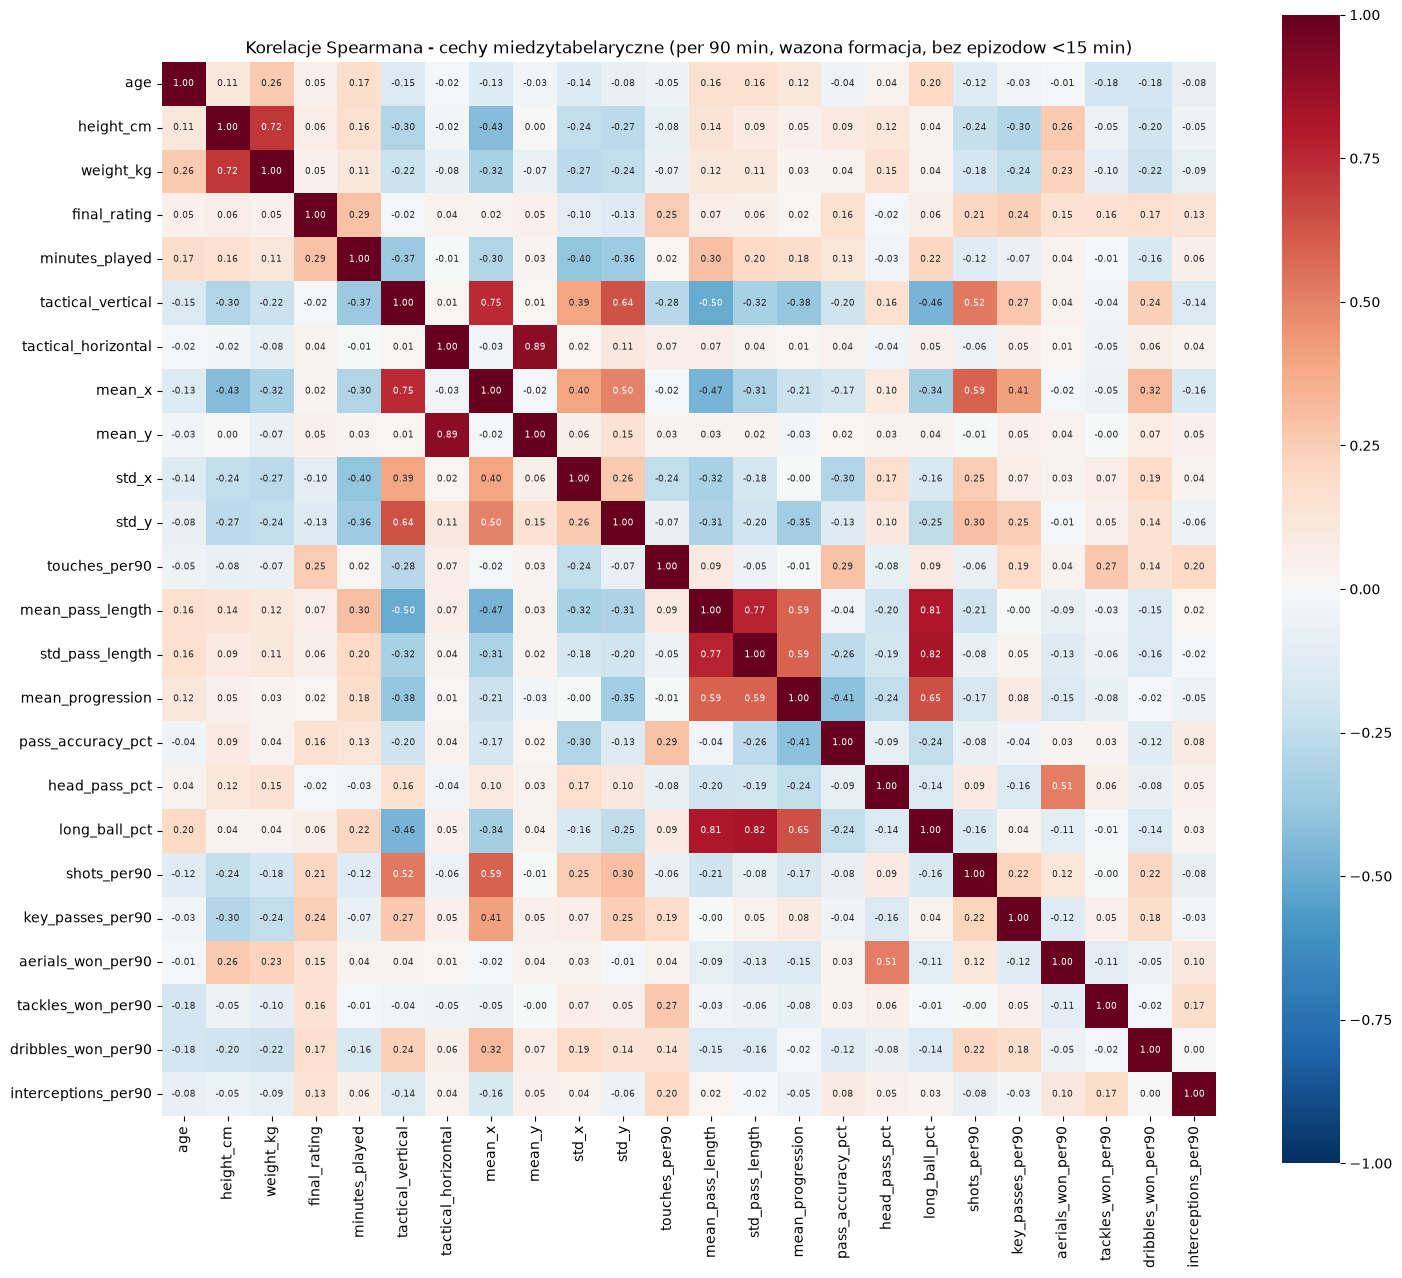

=== NAJSILNIEJSZE PARY MIEDZYTABELARYCZNE (player_match_df, cechy per 90 min) ===
  tactical_horizontal    <-> mean_y                 r = +0.891
  std_pass_length        <-> long_ball_pct          r = +0.821
  mean_pass_length       <-> long_ball_pct          r = +0.806
  mean_pass_length       <-> std_pass_length        r = +0.770
  tactical_vertical      <-> mean_x                 r = +0.745
  height_cm              <-> weight_kg              r = +0.716
  mean_progression       <-> long_ball_pct          r = +0.646
  tactical_vertical      <-> std_y                  r = +0.638
  std_pass_length        <-> mean_progression       r = +0.589
  mean_pass_length       <-> mean_progression       r = +0.588
  mean_x                 <-> shots_per90            r = +0.587
  tactical_vertical      <-> shots_per90            r = +0.524
  head_pass_pct          <-> aerials_won_per90      r = +0.508
  tactical_vertical      <-> mean_pass_length       r = -0.503

=== KORELACJE CECH FIZYCZNYCH PO DE

In [160]:
# Macierz korelacji Spearmana na tabeli miedzytabelarycznej player_match_df
corr_matrix = player_match_df[selected_cols].corr(method="spearman")

plt.figure(figsize=(15, 13))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, square=True, annot_kws={"size": 6.5},
)
plt.title("Korelacje Spearmana - cechy miedzytabelaryczne (per 90 min, wazona formacja, bez epizodow <15 min)")
plt.tight_layout()
plt.savefig(FIGURES / "korelacje.png", dpi=130)
plt.show()

pairs = []
for a, b in itertools.combinations(selected_cols, 2):
    pairs.append((a, b, corr_matrix.loc[a, b]))
pairs.sort(key=lambda t: -abs(t[2]))

print("=== NAJSILNIEJSZE PARY MIEDZYTABELARYCZNE (player_match_df, cechy per 90 min) ===")
for a, b, r in pairs[:14]:
    print(f"  {a:<22} <-> {b:<22} r = {r:+.3f}")

print()
print(f"=== KORELACJE CECH FIZYCZNYCH PO DEDUPLIKACJI GRACZY (n={len(player_career_df)} unikalnych zawodnikow) ===")
career_corr = player_career_df[selected_cols].corr(method="spearman")
print(f"  height_cm <-> weight_kg (unikalni gracze): r = {career_corr.loc['height_cm', 'weight_kg']:+.3f}")
for phys_col in ["height_cm", "weight_kg", "age"]:
    relations = [
        (phys_col, other_col, career_corr.loc[phys_col, other_col])
        for other_col in selected_cols
        if other_col not in ["age", "height_cm", "weight_kg"]
    ]
    relations.sort(key=lambda t: -abs(t[2]))
    top4_str = ", ".join(f"{b} ({r:+.2f})" for _, b, r in relations[:4])
    print(f"  {phys_col:<10} -> {top4_str}")

# Porownawczo: korelacje na poziomie pojedynczego zdarzenia (po oczyszczeniu z kodow)
event_corr = events_all[selected_event_cols].corr(method="spearman")
event_pairs = [
    (a, b, event_corr.loc[a, b])
    for a, b in itertools.combinations(selected_event_cols, 2)
]
event_pairs.sort(key=lambda t: -abs(t[2]))
print()
print("=== TOP 6 PAR NA POZIOMIE ZDARZEN (events_all po dodaniu progresji i graczy) ===")
for a, b, r in event_pairs[:6]:
    print(f"  {a:<22} <-> {b:<22} r = {r:+.3f}")


## 5. Ranking trójek (R² płaszczyzny)

Dla każdej trójki cech międzytabelarycznych w `player_match_df` dopasowujemy płaszczyznę najmniejszych kwadratów — sprawdzamy trzy możliwe kierunki i bierzemy najlepszy R². Ranking + podsumowanie wizualne par i trójek.


In [161]:
# Ranking trojek na tabeli miedzytabelarycznej player_match_df.
# Funkcja plane_r2 jest zdefiniowana w sekcji 1.
triplets = []
for a, b, c in itertools.combinations(selected_cols, 3):
    sub_df = player_match_df[[a, b, c]].dropna()
    if len(sub_df) < 50:
        continue

    best_triplet = (0.0, c, a, b)
    for target_col in (a, b, c):
        other_cols = [k for k in (a, b, c) if k != target_col]
        r2 = plane_r2(sub_df, other_cols[0], other_cols[1], target_col)
        if r2 > best_triplet[0]:
            best_triplet = (r2, target_col, other_cols[0], other_cols[1])

    triplets.append(best_triplet)

triplets.sort(key=lambda t: -t[0])

print(f"sprawdzono trojek miedzytabelarycznych: {len(triplets)}")
print()
print("=== TOP 10 TROJEK OGOLNIE ===")
for r2, target_col, x1, x2 in triplets[:10]:
    print(f"  {target_col:<22} ~ {x1:<22} + {x2:<22} R2 = {r2:.4f}")

# Osobno: co najlepiej wyjasnia ocene meczowa final_rating?
rating_triplets = []
non_rating_cols = [k for k in selected_cols if k != "final_rating"]
for x1, x2 in itertools.combinations(non_rating_cols, 2):
    sub_df = player_match_df[[x1, x2, "final_rating"]].dropna()
    rating_triplets.append((plane_r2(sub_df, x1, x2, "final_rating"), "final_rating", x1, x2))
rating_triplets.sort(key=lambda t: -t[0])

print()
print("=== TOP 5 TROJEK WYJASNIAJACYCH OCENE MECZOWA (final_rating) ===")
for r2, target_col, x1, x2 in rating_triplets[:5]:
    print(f"  {target_col:<22} ~ {x1:<22} + {x2:<22} R2 = {r2:.4f}")


sprawdzono trojek miedzytabelarycznych: 2024

=== TOP 10 TROJEK OGOLNIE ===
  mean_pass_length       ~ std_x                  + long_ball_pct          R2 = 0.8391
  mean_y                 ~ tactical_horizontal    + std_y                  R2 = 0.8317
  tactical_horizontal    ~ mean_y                 + head_pass_pct          R2 = 0.8313
  tactical_horizontal    ~ mean_y                 + touches_per90          R2 = 0.8311
  tactical_horizontal    ~ mean_y                 + shots_per90            R2 = 0.8311
  mean_y                 ~ final_rating           + tactical_horizontal    R2 = 0.8300
  mean_y                 ~ minutes_played         + tactical_horizontal    R2 = 0.8297
  tactical_horizontal    ~ mean_y                 + pass_accuracy_pct      R2 = 0.8296
  mean_y                 ~ tactical_horizontal    + std_x                  R2 = 0.8295
  mean_y                 ~ tactical_horizontal    + tackles_won_per90      R2 = 0.8295

=== TOP 5 TROJEK WYJASNIAJACYCH OCENE MECZOWA (final_

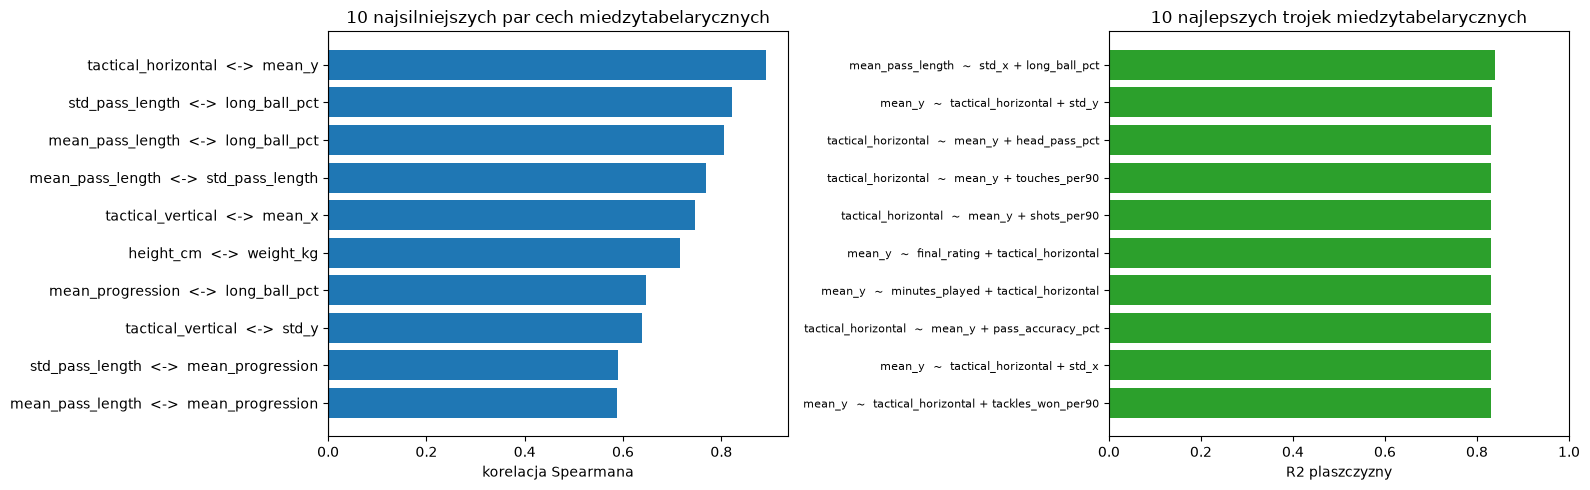

In [162]:
# Podsumowanie wizualne sekcji 4 i 5: najsilniejsze pary i najlepsze trojki obok siebie
fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(16, 5))

# --- lewy panel: pary ---
top_pairs = pairs[:10]
left_ax.barh(
    [f"{a}  <->  {b}" for a, b, _ in top_pairs][::-1],
    [r for _, _, r in top_pairs][::-1],
)
left_ax.axvline(0, color="black", linewidth=0.8)
left_ax.set_xlabel("korelacja Spearmana")
left_ax.set_title("10 najsilniejszych par cech miedzytabelarycznych")

# --- prawy panel: trojki ---
top_triplets = triplets[:10]
right_ax.barh(
    [f"{target_col}  ~  {x1} + {x2}" for r2, target_col, x1, x2 in top_triplets][::-1],
    [r2 for r2, _, _, _ in top_triplets][::-1],
    color="tab:green",
)
right_ax.set_xlabel("R2 plaszczyzny")
right_ax.set_title("10 najlepszych trojek miedzytabelarycznych")
right_ax.set_xlim(0, 1)
right_ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(FIGURES / "pary_i_trojki.png", dpi=130)
plt.show()


## 6. Wykresy 3D

Cztery ciekawe trójki międzytabelaryczne na płaszczyźnie 3D: najlepsze dopasowania ogólne oraz najlepsze wyjaśnienie `final_rating`.


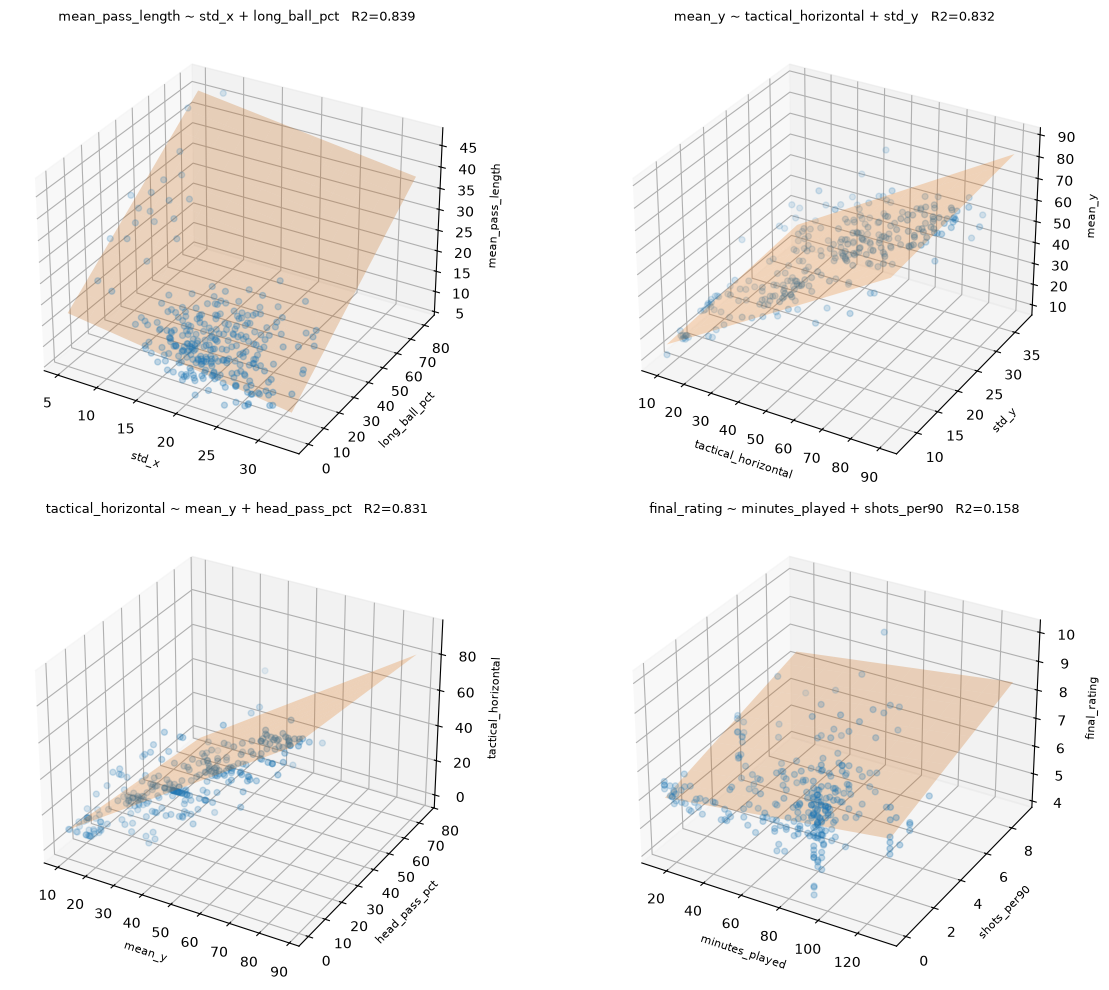

In [163]:
# Cztery reprezentatywne trojki miedzytabelaryczne na figurze 2x2
# Bierzemy 3 najlepsze ogolnie (z roznymi celami) + najlepsza trojke dla final_rating
selected_3d_triplets = []
used_targets = set()
for triplet in triplets:
    if triplet[1] not in used_targets:
        selected_3d_triplets.append(triplet)
        used_targets.add(triplet[1])
    if len(selected_3d_triplets) == 3:
        break
selected_3d_triplets.append(rating_triplets[0])

fig = plt.figure(figsize=(13, 10))

for idx, (r2, target_col, x1, x2) in enumerate(selected_3d_triplets, start=1):
    sub_df = player_match_df[[x1, x2, target_col]].dropna()

    X = np.column_stack([np.ones(len(sub_df)), sub_df[x1], sub_df[x2]])
    beta, *_ = np.linalg.lstsq(X, sub_df[target_col].to_numpy(), rcond=None)

    ax = fig.add_subplot(2, 2, idx, projection="3d")
    ax.scatter(sub_df[x1], sub_df[x2], sub_df[target_col], s=18, alpha=0.55)

    xs = np.linspace(sub_df[x1].min(), sub_df[x1].max(), 12)
    ys = np.linspace(sub_df[x2].min(), sub_df[x2].max(), 12)
    grid_x, grid_y = np.meshgrid(xs, ys)
    grid_z = beta[0] + beta[1] * grid_x + beta[2] * grid_y
    ax.plot_surface(grid_x, grid_y, grid_z, alpha=0.25, color="tab:orange")

    ax.set_xlabel(x1, fontsize=8)
    ax.set_ylabel(x2, fontsize=8)
    ax.set_zlabel(target_col, fontsize=8)
    ax.set_title(f"{target_col} ~ {x1} + {x2}   R2={r2:.3f}", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES / "trojki_3d.png", dpi=110)
plt.show()


## 7. Rekonstrukcja posiadania

Posiadanie = ciąg kolejnych zdarzeń tej samej drużyny w tym samym meczu. Bez serii rzutów karnych (period 5) i zdarzeń przed/po meczu.


In [164]:
# Rekonstrukcja posiadania na wszystkich meczach (poziom analizy sekwencji gry).
ev = events_all.copy()
ev = ev.sort_values(["match_id", "event_index"]).reset_index(drop=True)

# bez serii rzutow karnych (period 5) i bez zdarzen przed/po meczu (14, 16)
n_before = len(ev)
ev = ev[~ev["period_value"].isin([5, 14, 16])]
ev = ev[ev["team_id"].notna()]
print(f"zdarzen po odfiltrowaniu: {len(ev)} (usunieto {n_before - len(ev)})")
print()

ev["has_goal"] = ev["is_goal"] == True
ev["has_shot"] = ev["is_shot"] == True
ev["is_pass"] = ev["event_type"] == "Pass"

# posiadanie = ciag kolejnych zdarzen tej samej druzyny W TYM SAMYM MECZU.
team_change = ev["team_id"] != ev["team_id"].shift()
match_change = ev["match_id"] != ev["match_id"].shift()
ev["possession_id"] = (team_change | match_change).cumsum()

# pole karne: x >= 83 ORAZ y w [21, 79]; bez zdarzen strzalu (zeby uniknac tautologii)
ev["in_box"] = (ev["x"] >= 83) & (ev["y"].between(21, 79))
ev["box_entry"] = ev["in_box"] & (~ev["has_shot"])

possessions = ev.groupby(["match_id", "possession_id"]).agg(
    events_count=("event_index", "size"),
    passes_count=("is_pass", "sum"),
    start_x=("x", "first"),
    end_x=("x", "last"),
    mean_rating=("player_rating", "mean"),
    box_entry=("box_entry", "max"),
    has_shot=("has_shot", "max"),
    has_goal=("has_goal", "max"),
).reset_index()
possessions["progression_x"] = possessions["end_x"] - possessions["start_x"]

print("posiadan:", len(possessions))
print("ze strzalem:", int(possessions["has_shot"].sum()))
print("z golem:", int(possessions["has_goal"].sum()))
print()
print(f"P(has_shot | possession) = {100 * possessions['has_shot'].mean():.2f}%")
print(f"P(has_goal | possession) = {100 * possessions['has_goal'].mean():.2f}%")


zdarzen po odfiltrowaniu: 16184 (usunieto 65)

posiadan: 5074
ze strzalem: 262
z golem: 36

P(has_shot | possession) = 5.16%
P(has_goal | possession) = 0.71%


## 8. Co zwiększa szansę na strzał

Prawdopodobieństwa warunkowe z 95% przedziałami ufności Wilsona.


In [165]:
# Warunkowe prawdopodobienstwa P(has_shot | cecha posiadania)
# Funkcje wilson_ci() i cond_table() sa zdefiniowane w sekcji 1.
possessions["passes_bin"] = pd.cut(
    possessions["passes_count"],
    [-1, 0, 1, 2, 4, 8, 100],
    labels=["0", "1", "2", "3-4", "5-8", "9+"],
)
possessions["start_zone"] = pd.cut(
    possessions["start_x"],
    [0, 33, 66, 100],
    labels=["own_third", "mid_third", "final_third"],
)

for col in ["box_entry", "passes_bin", "start_zone"]:
    print(f"=== P(has_shot) wg {col} ===")
    print(cond_table(possessions, col, target="has_shot").to_string())
    print()


=== P(has_shot) wg box_entry ===
           cases  hits    P %    95% CI
box_entry                              
False       4625   211   4.56   4.0-5.2
True         449    51  11.36  8.7-14.6

=== P(has_shot) wg passes_bin ===
            cases  hits   P %    95% CI
passes_bin                             
0            2378   105  4.42   3.7-5.3
1             993    45  4.53   3.4-6.0
2             456    21  4.61   3.0-6.9
3-4           486    30  6.17   4.4-8.7
5-8           435    33  7.59  5.5-10.5
9+            326    28  8.59  6.0-12.1

=== P(has_shot) wg start_zone ===
             cases  hits    P %     95% CI
start_zone                                
own_third     1977    30   1.52    1.1-2.2
mid_third     1848    55   2.98    2.3-3.9
final_third   1129   176  15.59  13.6-17.8



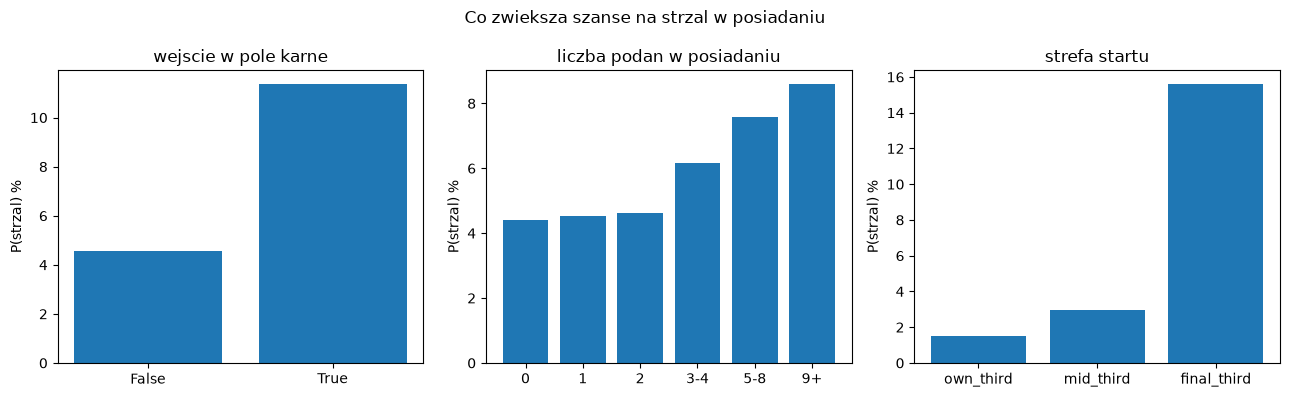

In [166]:
# Trzy panele: co zwieksza szanse na strzal
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, title in [
    (axes[0], "box_entry", "wejscie w pole karne"),
    (axes[1], "passes_bin", "liczba podan w posiadaniu"),
    (axes[2], "start_zone", "strefa startu"),
]:
    summary_df = cond_table(possessions, col, target="has_shot")
    ax.bar([str(i) for i in summary_df.index], summary_df["P %"])
    ax.set_title(title)
    ax.set_ylabel("P(strzal) %")

plt.suptitle("Co zwieksza szanse na strzal w posiadaniu")
plt.tight_layout()
plt.savefig(FIGURES / "posiadanie_strzal.png", dpi=130)
plt.show()


## 9. Które podania kończą się strzałem (z cechami odbiorcy z `players_all`)

Analiza na poziomie pojedynczego podania: strefa zakończenia, typ podania oraz wzrost adresata podania (`receiver_height_cm` z tabeli `players_all`).


In [167]:
# Poziom podania: ktore podania koncza sie strzalem w tej samej akcji
ev["shot_event_idx"] = ev["event_index"].where(ev["has_shot"])
ev["shot_event_idx"] = ev.groupby(["match_id", "possession_id"])["shot_event_idx"].transform("max")

passes_df = ev[ev["is_pass"] & (ev["outcome_type"] == "Successful")].copy()
passes_df["leads_to_shot"] = passes_df["shot_event_idx"] > passes_df["event_index"]

passes_df["end_zone"] = pd.cut(
    passes_df["end_x"],
    [0, 33, 66, 83, 100],
    labels=["own_third", "mid_third", "final_third", "penalty_box"],
)
passes_df["receiver_height_bin"] = pd.cut(
    passes_df["receiver_height_cm"],
    [0, 178, 185, 220],
    labels=["<=178 cm", "179-185 cm", "186+ cm"],
)

print("podan celnych:", len(passes_df))
print("z nich konczy sie strzalem:", int(passes_df["leads_to_shot"].sum()))
print(f"bazowo: {100 * passes_df['leads_to_shot'].mean():.2f}%")
print()
print("=== wg strefy, w ktorej konczy sie podanie ===")
print(cond_table(passes_df, "end_zone", target="leads_to_shot").to_string())
print()
print("=== wg typu podania ===")
for col in ["is_through_ball", "is_cross"]:
    print(f"-- {col}")
    print(cond_table(passes_df, col, target="leads_to_shot").to_string())
    print()

print("=== wg wzrostu adresata podania (players_all -> receiver_height_cm) przy dlugich pilkach/dosrodkowaniach ===")
high_passes = passes_df[passes_df["is_long_ball"] | passes_df["is_cross"]]
print(cond_table(high_passes, "receiver_height_bin", target="leads_to_shot").to_string())


podan celnych: 8887
z nich konczy sie strzalem: 743
bazowo: 8.36%

=== wg strefy, w ktorej konczy sie podanie ===
             cases  hits    P %     95% CI
end_zone                                  
own_third     2283   111   4.86    4.1-5.8
mid_third     4444   281   6.32    5.6-7.1
final_third   1629   215  13.20  11.6-14.9
penalty_box    531   136  25.61  22.1-29.5

=== wg typu podania ===
-- is_through_ball
                 cases  hits    P %     95% CI
is_through_ball                               
False             8866   732   8.26    7.7-8.8
True                21    11  52.38  32.4-71.7

-- is_cross
          cases  hits    P %     95% CI
is_cross                               
False      8825   713   8.08    7.5-8.7
True         62    30  48.39  36.4-60.6

=== wg wzrostu adresata podania (players_all -> receiver_height_cm) przy dlugich pilkach/dosrodkowaniach ===
                     cases  hits    P %     95% CI
receiver_height_bin                               
<=178 cm   

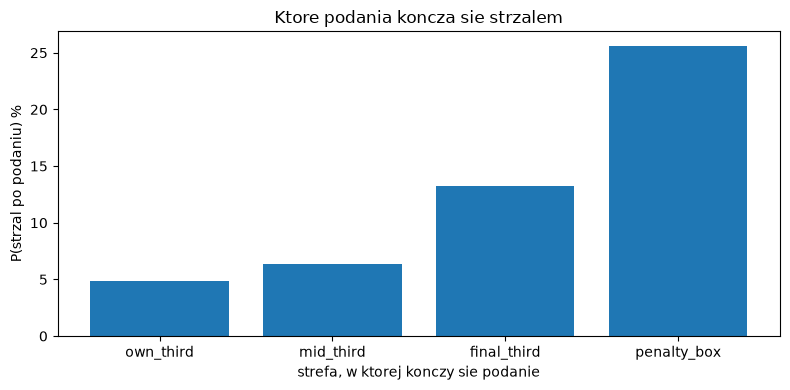

liczebnosci:
             cases  hits
end_zone                
own_third     2283   111
mid_third     4444   281
final_third   1629   215
penalty_box    531   136


In [168]:
# Wykres: P(strzal po podaniu) wg strefy zakonczenia podania
summary_df = cond_table(passes_df, "end_zone", target="leads_to_shot")

plt.figure(figsize=(8, 4))
plt.bar([str(i) for i in summary_df.index], summary_df["P %"])
plt.ylabel("P(strzal po podaniu) %")
plt.xlabel("strefa, w ktorej konczy sie podanie")
plt.title("Ktore podania koncza sie strzalem")
plt.tight_layout()
plt.savefig(FIGURES / "podania_strzal.png", dpi=130)
plt.show()

print("liczebnosci:")
print(summary_df[["cases", "hits"]].to_string())


## 10. Pozycje z formacji

Ustawienie wyjściowe obu drużyn z tabeli `formations` (skala 0–10 przeskalowana do 0–100). Uwaga na osie: w tej tabeli wzdłuż boiska idzie `vertical` (0 = własna bramka), a `horizontal` to szerokość — odwrotnie niż w zdarzeniach, gdzie wzdłuż boiska idzie `x`.


formacje w meczu: [ 343  352 4231]
zawodnikow w ustawieniu wyjsciowym: 22


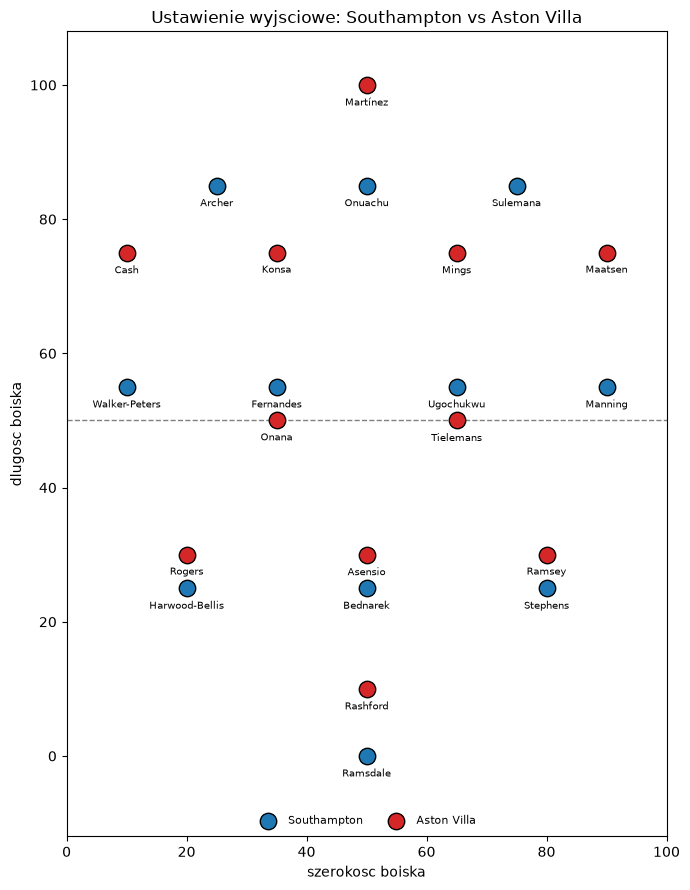

In [169]:
# Pozycje z formacji - ustawienie wyjsciowe obu druzyn (jeden mecz, tabela 'formations' z sekcji 1)
starting_lineup = formations[formations["start_minute_expanded"] == 0]

print("formacje w meczu:", formations["formation_name"].unique())
print("zawodnikow w ustawieniu wyjsciowym:", len(starting_lineup))

fig, ax = plt.subplots(figsize=(7, 9))
colors = {"home": "tab:blue", "away": "tab:red"}

for side in ["home", "away"]:
    side_df = starting_lineup[starting_lineup["team_side"] == side]

    # horizontal i vertical sa w skali 0-10 -> mnozymy przez 10
    xs = side_df["horizontal"] * 10
    ys = side_df["vertical"] * 10
    if side == "away":
        ys = 100 - ys  # lustro, zeby druzyny graly naprzeciw siebie

    # puste punkty tylko po to, zeby legenda miala co pokazac
    ax.scatter([], [], s=140, c=colors[side], edgecolors="black", label=side_df["team_name"].iloc[0])
    ax.scatter(xs, ys, s=140, c=colors[side], edgecolors="black", zorder=3)

    for x, y, player_name in zip(xs, ys, side_df["player_name"]):
        # podpis POD punktem, inaczej nazwisko zaslania znacznik
        ax.annotate(
            player_name.split()[-1],
            (x, y),
            fontsize=7,
            ha="center",
            va="top",
            xytext=(0, -9),
            textcoords="offset points",
            zorder=4,
        )

ax.axhline(50, color="gray", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_ylim(-12, 108)
ax.set_xlabel("szerokosc boiska")
ax.set_ylabel("dlugosc boiska")
ax.set_title("Ustawienie wyjsciowe: " + " vs ".join(starting_lineup["team_name"].unique()))
ax.legend(loc="lower center", ncols=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURES / "formacje.png", dpi=130)
plt.show()


## 11. Momentum drużyny

`team_stats` per minuta: narastające dotknięcia i podania oraz przewaga w oknach 5-minutowych.


metryki w team_stats: 35
stat_name
ratings           191
touches           181
possession        149
passSuccess       143
passesTotal       143
passesAccurate    130



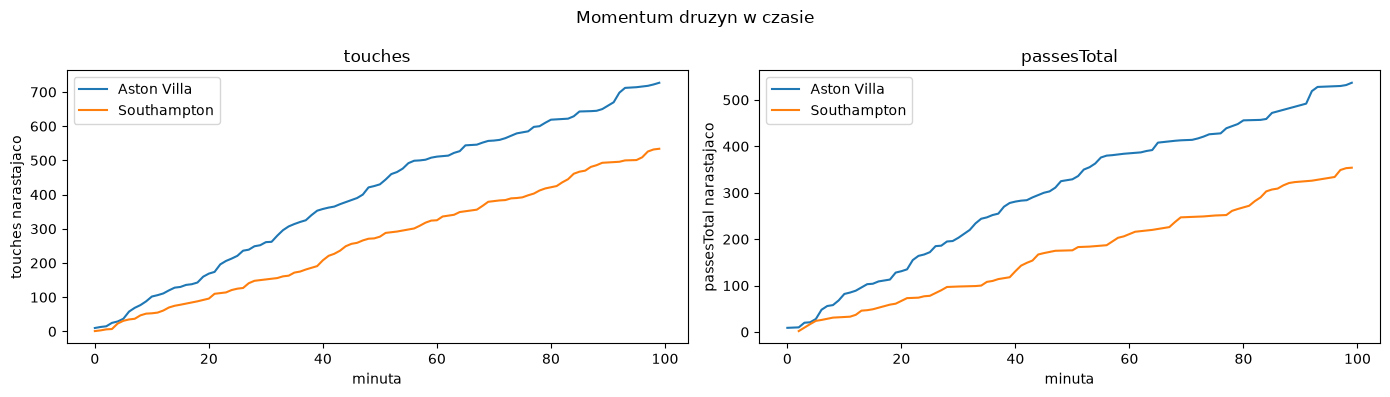

In [170]:
# Momentum druzyn: narastajace dotkniecia i podania na jednej figurze
print("metryki w team_stats:", team_stats["stat_name"].nunique())
print(team_stats["stat_name"].value_counts().head(6).to_string())
print()

# UWAGA: touches i passesTotal to PRZYROSTY na minute -> cumsum().
# 'ratings' to wartosc narastajaca (snapshot) - tego nie sumujemy.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, metric in zip(axes, ["touches", "passesTotal"]):
    for team_name, team_df in team_stats[team_stats["stat_name"] == metric].groupby("team_name"):
        team_df = team_df.sort_values("minute")
        ax.plot(team_df["minute"], team_df["value"].cumsum(), label=team_name)

    ax.set_xlabel("minuta")
    ax.set_ylabel(metric + " narastajaco")
    ax.set_title(metric)
    ax.legend()

plt.suptitle("Momentum druzyn w czasie")
plt.tight_layout()
plt.savefig(FIGURES / "momentum.png", dpi=120)
plt.show()


In [171]:
# Okna 5-minutowe: kto mial przewage w danym fragmencie meczu
windows_df = team_stats[team_stats["stat_name"] == "touches"].copy()
windows_df["window_5m"] = (windows_df["minute"] // 5) * 5

windows_table = windows_df.groupby(["window_5m", "team_name"])["value"].sum().unstack()

print("dotkniecia pilki w oknach 5-minutowych:")
print(windows_table.head(12).to_string())

if windows_table.shape[1] == 2:
    diff_series = windows_table.iloc[:, 0] - windows_table.iloc[:, 1]
    print()
    print("przewaga (", windows_table.columns[0], "-", windows_table.columns[1], "):")
    print(diff_series.head(12).to_string())


dotkniecia pilki w oknach 5-minutowych:
team_name  Aston Villa  Southampton
window_5m                          
0                 29.0         23.0
5                 59.0         29.0
10                40.0         23.0
15                32.0         17.0
20                53.0         29.0
25                39.0         29.0
30                55.0         13.0
35                46.0         28.0
40                19.0         58.0
45                53.0         23.0
50                51.0         23.0
55                32.0         29.0

przewaga ( Aston Villa - Southampton ):
window_5m
0      6.0
5     30.0
10    17.0
15    15.0
20    24.0
25    10.0
30    42.0
35    18.0
40   -39.0
45    30.0
50    28.0
55     3.0


## 12. Rzuty karne

`is_penalty` flaguje całą sytuację (faul, kartka, `PenaltyFaced`), nie sam strzał. Sekwencje przed karnym.


In [172]:
# Rzuty karne - UWAGA: is_penalty to flaga CALEJ SYTUACJI, nie strzal z karnego.
# Flaga obejmuje faul, kartke i PenaltyFaced bramkarza.
penalty_shots = ev[ev["is_penalty"] & ev["has_shot"]]

print("zdarzen z flaga is_penalty:", int(ev["is_penalty"].sum()))
print("z tego strzalow z karnego :", len(penalty_shots))
print("z tego goli               :", int(penalty_shots["has_goal"].sum()))
print()

penalties_per_match = penalty_shots.groupby("match_id").size()
print("meczow z rzutem karnym:", len(penalties_per_match), "z", ev["match_id"].nunique())
print(penalties_per_match.to_string())


zdarzen z flaga is_penalty: 26
z tego strzalow z karnego : 6
z tego goli               : 4

meczow z rzutem karnym: 5 z 10
match_id
1821123    2
1993983    1
1995426    1
2002449    1
2029242    1


In [173]:
# Co poprzedza strzal z karnego - 4 zdarzenia wstecz
print("=== sekwencja przed kazdym strzalem z karnego ===")

for _, shot_row in penalty_shots.iterrows():
    prev_events = ev[
        (ev["match_id"] == shot_row["match_id"])
        & (ev["event_index"] < shot_row["event_index"])
        & (ev["event_index"] >= shot_row["event_index"] - 4)
    ]

    print()
    print(f"mecz {shot_row['match_id']}, {shot_row['expanded_minute']}. min - karny: {shot_row['player_name']} ({shot_row['team_name']})")

    for _, ev_row in prev_events.iterrows():
        player_label = ev_row["player_name"] if pd.notna(ev_row["player_name"]) else "-"
        print(f"   {ev_row['expanded_minute']:>3}. min  {str(ev_row['event_type']):<16} {player_label}")


=== sekwencja przed kazdym strzalem z karnego ===

mecz 1821123, 70. min - karny: Marco Asensio (Aston Villa)
    69. min  Foul             Ollie Watkins
    69. min  Foul             Jan Bednarek
    69. min  Card             Jan Bednarek
    70. min  PenaltyFaced     Aaron Ramsdale

mecz 1821123, 95. min - karny: Marco Asensio (Aston Villa)
    93. min  BallTouch        Donyell Malen
    93. min  Foul             John McGinn
    93. min  Foul             Jack Stephens
    95. min  PenaltyFaced     Aaron Ramsdale

mecz 1993983, 10. min - karny: Kylian Mbappé (Real Madrid)
     9. min  Pass             Yan Diomande
     9. min  TakeOn           Kylian Mbappé
     9. min  Foul             Kylian Mbappé
     9. min  Foul             Matteo Prati

mecz 1995426, 65. min - karny: Niclas Füllkrug (Werder Bremen)
    64. min  Pass             Mitchell Weiser
    65. min  SavedShot        Olivier Deman
    65. min  Foul             -
    65. min  Foul             Laurin Curda

mecz 2002449, 21

## 13. Big chance

Prawdopodobieństwo stuprocentowej sytuacji w zależności od cech posiadania.


In [174]:
# BIG CHANCE - doklejenie do posiadan (razem z czasem trwania)
extra_poss_stats = ev.groupby(["match_id", "possession_id"]).agg(
    big_chance=("is_big_chance", "max"),
    duration_min=("expanded_minute", lambda s: s.max() - s.min()),
).reset_index()

possessions = possessions.drop(columns=[c for c in ["big_chance", "duration_min"] if c in possessions.columns])
possessions = possessions.merge(extra_poss_stats, on=["match_id", "possession_id"], how="left")

print("big chance w zbiorze zdarzen:", int(ev["is_big_chance"].sum()))
print("posiadan z big chance      :", int(possessions["big_chance"].sum()))
print()

for col in ["box_entry", "passes_bin", "start_zone"]:
    print(f"=== P(big_chance) wg {col} ===")
    print(cond_table(possessions, col, target="big_chance").to_string())
    print()


big chance w zbiorze zdarzen: 49
posiadan z big chance      : 49

=== P(big_chance) wg box_entry ===
           cases  hits   P %   95% CI
box_entry                            
False       4625    37  0.80  0.6-1.1
True         449    12  2.67  1.5-4.6

=== P(big_chance) wg passes_bin ===
            cases  hits   P %   95% CI
passes_bin                            
0            2378    19  0.80  0.5-1.2
1             993     7  0.70  0.3-1.4
2             456     6  1.32  0.6-2.8
3-4           486     3  0.62  0.2-1.8
5-8           435     8  1.84  0.9-3.6
9+            326     6  1.84  0.8-4.0

=== P(big_chance) wg start_zone ===
             cases  hits   P %   95% CI
start_zone                             
own_third     1977     4  0.20  0.1-0.5
mid_third     1848    17  0.92  0.6-1.5
final_third   1129    28  2.48  1.7-3.6



## 14. Ranking cech per cel

Osobny ranking par cech dla celów binarnych na poziomie posiadania (`has_shot`, `has_goal`, `big_chance` — z uwzględnieniem `progression_x` i `mean_rating` z `players_all`) oraz dla ciągłego celu `final_rating` na poziomie zawodnika.


In [175]:
# Ranking par cech dla KAZDEGO celu osobno (poziom posiadania + cechy z players_all).
possession_features = [
    "passes_count", "events_count", "start_x",
    "progression_x", "duration_min", "box_entry", "mean_rating",
]
possession_targets = ["has_shot", "has_goal", "big_chance"]

for target_col in possession_targets:
    target_pairs = []

    for x1, x2 in itertools.combinations([k for k in possession_features if k != target_col], 2):
        sub_df = possessions[[x1, x2, target_col]].dropna()
        if len(sub_df) < 50:
            continue
        target_pairs.append((plane_r2(sub_df, x1, x2, target_col), x1, x2))

    target_pairs.sort(key=lambda t: -t[0])

    print(f"=== TOP 3 pary cech dla celu '{target_col}' (posiadan: {len(possessions)}) ===")
    for r2, x1, x2 in target_pairs[:3]:
        print(f"  {target_col:<12} ~ {x1:<15} + {x2:<15} R2 = {r2:.4f}")
    print()


=== TOP 3 pary cech dla celu 'has_shot' (posiadan: 5074) ===
  has_shot     ~ start_x         + progression_x   R2 = 0.0754
  has_shot     ~ events_count    + start_x         R2 = 0.0606
  has_shot     ~ start_x         + duration_min    R2 = 0.0568

=== TOP 3 pary cech dla celu 'has_goal' (posiadan: 5074) ===
  has_goal     ~ start_x         + mean_rating     R2 = 0.0162
  has_goal     ~ duration_min    + mean_rating     R2 = 0.0149
  has_goal     ~ events_count    + mean_rating     R2 = 0.0134

=== TOP 3 pary cech dla celu 'big_chance' (posiadan: 5074) ===
  big_chance   ~ start_x         + progression_x   R2 = 0.0164
  big_chance   ~ events_count    + start_x         R2 = 0.0124
  big_chance   ~ start_x         + mean_rating     R2 = 0.0115



## Wnioski i uwagi metodologiczne

1. **Poziom międzytabelaryczny (`player_match_df`) eliminuje pseudoreplikację i artefakty geometryczne:** połączenie `players_all` + `formations_all` + zagregowanego `events_all` + `player_stats_all` pozwala badać realne powiązania boiskowe na wspólnej skali.
2. **Zachowanie wymiarowości czasu, przestrzeni i zmienności (poprawki 1–4):**
   - **Normalizacja per 90 minut (`*_per90`) i filtr czasu gry (`minutes_played >= 15`)** oddzielają intensywność boiskową od samego faktu dłuższego przebywania na murawie.
   - **Poprawne mianowniki odsetków podań (`head_pass_pct`, `long_ball_pct` wyłącznie dla `is_pass == True`)** eliminują zniekształcenia u graczy z dużym udziałem akcji niebędących podaniami.
   - **Ważona czasem pozycja taktyczna (`tactical_vertical`, `tactical_horizontal`) oraz rzeczywiste położenie i rozrzut kontaktów (`mean_x`, `mean_y`, `std_x`, `std_y`, `std_pass_length`)** zachowują informację o zmianach ustawienia w trakcie meczu i mobilności zawodnika.
   - **Uwzględnienie `interceptions_per90` oraz deduplikacja do unikalnych graczy (`player_career_df`)** przy korelacjach cech fizycznych (`height_cm`, `weight_kg`, `age`) zapobiegają wielokrotnemu ważeniu tych samych zawodników z kilku meczów.
3. **Cechy progresji zamiast surowych `end_x`, `end_y`:** zastąpienie współrzędnych końcowych przyrostami (`dx`, `dy`, `goal_progression`) oraz usunięcie kodów słownikowych (`event_type_value`, `outcome_type_value`, `second`) oczyszcza macierz korelacji z pozornych zależności.
